# Rhythm features: SVM-RBF

How well do the rhythm features recognise the eight dances, how much of that comes from the tempo alone, and what happens when only the tempo of the audio changes?

The notebook tests two feature sets with SVM-RBF: the rhythm features (cyclic tempogram, bar ratios, PLP confidence and PLP alignment, 20 numbers) and the tempo alone (`tau_hat`). The folds, the tuning and the stretched audio are the same as in the timbral notebooks. `Rhythm_Random_Forest.ipynb` does the same with Random Forest.

## 1. Files

The notebook needs the audio in `BallroomData/`. It saves the rhythm features of all 13 versions in `rhythm_conditions.csv` (the other rhythm notebook reuses it) and its tables and figures in `results/rhythm_svm_rbf/`. The comparison at the end also reads the timbral results from `results/svm_rbf/`.

In [1]:
from dataclasses import dataclass, field
from pathlib import Path
import os
import platform
import time
import warnings

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from joblib import Parallel, delayed
from scipy.interpolate import interp1d
from scipy.signal import get_window
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# harmless librosa 1.0 warning
warnings.filterwarnings('ignore', message='The `(hop_length|n_fft)` parameter is deprecated', category=FutureWarning)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180})
pd.set_option('display.max_columns', 30)
display(pd.Series({'python': platform.python_version(), 'numpy': np.__version__,
                   'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                   'librosa': librosa.__version__}, name='version').to_frame())

,version
python,3.12.13
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
librosa,1.0.0


## 2. Settings

In [2]:
PROJECT_DIR = Path('.')
DATASET_DIR = Path('BallroomData')

MODEL_NAME = 'SVM–RBF'
OTHER_MODEL_NAME = 'Random Forest'
FOLDS_PATH = PROJECT_DIR / 'folds.csv'
CONDITIONS_PATH = PROJECT_DIR / 'rhythm_conditions.csv'
RESULTS_DIR = PROJECT_DIR / 'results' / 'rhythm_svm_rbf'
OTHER_RESULTS_DIR = PROJECT_DIR / 'results' / 'rhythm_random_forest'
TIMBRAL_RESULTS_DIR = PROJECT_DIR / 'results' / 'svm_rbf'

EXPECTED_CLIPS = 698
RANDOM_SEED = 2026
OUTER_FOLDS = 5
INNER_FOLDS = 3
N_JOBS = 8                          # set to 1 if parallel runs give problems
IMPORTANCE_REPEATS = 5

VARIANTS = ['Default', 'Tuned']
METRICS = ['accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1']
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
MODEL_COLORS = {'Random Forest': BLUE, 'SVM–RBF': ORANGE}
SET_COLORS = {'Timbral': BLUE, 'Rhythm': ORANGE, 'Tempo only': AQUA}
SET_DIRS = {'Rhythm': 'rhythm', 'Tempo only': 'tempo_only'}

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f'{DATASET_DIR} not found. The rhythm notebooks compute their features from the '
                            'audio, so set DATASET_DIR to the BallroomData folder.')
for folder in list(SET_DIRS.values()) + ['comparison']:
    (RESULTS_DIR / folder / 'time_stretch').mkdir(parents=True, exist_ok=True)


def save(table, feature_set, name, **options):
    table.to_csv(RESULTS_DIR / SET_DIRS.get(feature_set, feature_set) / name, **options)


def save_figure(figure, feature_set, name):
    figure.savefig(RESULTS_DIR / SET_DIRS.get(feature_set, feature_set) / name, bbox_inches='tight')
    plt.show()

## 3. Clips and folds

The folder of every clip is its label, and the three Rumba folders are merged. The folds are the same as in the timbral notebooks: stratified by dance, with the 13 known duplicate pairs kept in the same fold. If `folds.csv` already exists, the cell checks that the folds are identical.

In [3]:
KNOWN_REPLICAS = [   # known duplicate pairs (Fire-08 and Fire-09 have different labels)
    ('Albums-AnaBelen_Veneo-11.wav', 'Albums-Chrisanne2-12.wav'),
    ('Albums-Fire-08.wav', 'Albums-Fire-09.wav'),
    ('Albums-Latin_Jam2-05.wav', 'Albums-Latin_Jam2-13.wav'),
    ('Albums-Secret_Garden-01.wav', 'Media-104705.wav'),
    ('Albums-AnaBelen_Veneo-03.wav', 'Albums-AnaBelen_Veneo-15.wav'),
    ('Albums-Ballroom_Magic-03.wav', 'Albums-Ballroom_Magic-18.wav'),
    ('Albums-Latin_Jam-04.wav', 'Albums-Latin_Jam-13.wav'),
    ('Albums-Latin_Jam-08.wav', 'Albums-Latin_Jam-14.wav'),
    ('Albums-Latin_Jam-06.wav', 'Albums-Latin_Jam-15.wav'),
    ('Albums-Latin_Jam2-02.wav', 'Albums-Latin_Jam2-14.wav'),
    ('Albums-Latin_Jam2-07.wav', 'Albums-Latin_Jam2-15.wav'),
    ('Albums-Latin_Jam3-02.wav', 'Media-103414.wav'),
    ('Media-103402.wav', 'Media-103415.wav'),
]


def find_clips(dataset_dir):
    rows = []
    for folder, _, files in os.walk(dataset_dir):
        for name in files:
            if name.lower().endswith('.wav') and not name.startswith('.'):
                style = os.path.basename(folder)
                rows.append({'filename': name, 'folder': style,
                             'label': 'Rumba' if style.startswith('Rumba') else style})
    return pd.DataFrame(rows).sort_values('filename').reset_index(drop=True)


def make_folds(clips):
    folds = clips[['filename', 'label']].sort_values('filename').reset_index(drop=True)
    group_of = {name: name.removesuffix('.wav') for name in folds['filename']}
    for first, second in KNOWN_REPLICAS:
        if first in group_of and second in group_of:
            group_of[second] = group_of[first]
    folds['group_id'] = folds['filename'].map(group_of)
    splitter = StratifiedGroupKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    folds['fold'] = -1
    for fold, (_, test_rows) in enumerate(splitter.split(folds, folds['label'], groups=folds['group_id']), start=1):
        folds.loc[test_rows, 'fold'] = fold
    return folds


clips = find_clips(DATASET_DIR)
class_labels = np.sort(clips['label'].unique())
assert clips['filename'].is_unique and len(clips) == EXPECTED_CLIPS and len(class_labels) == 8, \
    f'found {len(clips)} clips and {len(class_labels)} genres in {DATASET_DIR}'

folds = make_folds(clips)
assert (folds.groupby('group_id')['fold'].nunique() == 1).all(), 'a pair is split over two folds'
if FOLDS_PATH.is_file():
    assert pd.read_csv(FOLDS_PATH).equals(folds), f'{FOLDS_PATH} has different folds than the ones made here'
    print(f'{FOLDS_PATH} already exists and is identical to the folds made here')
else:
    folds.to_csv(FOLDS_PATH, index=False)
    print(f'saved {FOLDS_PATH}')
clips = clips.merge(folds[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')
print(f'{len(clips)} clips, {len(class_labels)} genres')
display(pd.crosstab(clips['fold'], clips['label'], margins=True))

folds.csv already exists and is identical to the folds made here
698 clips, 8 genres


label,ChaChaCha,Jive,Quickstep,Rumba,Samba,Tango,VienneseWaltz,Waltz,All
fold,,,,,,,,,
1,22,12,17,20,17,17,13,22,140
2,22,12,17,20,17,17,13,22,140
3,22,12,16,20,17,18,13,22,140
4,22,12,16,19,18,17,13,22,139
5,23,12,16,19,17,17,13,22,139
All,111,60,82,98,86,86,65,110,698


## 4. The rhythm features

Everything starts from the novelty curve (`librosa.onset.onset_strength`), which goes up whenever a note or drum hit starts. From it we compute a Fourier tempogram and an autocorrelation tempogram, with a window of 512 frames (about 12 s). The Fourier tempogram uses a zero-padded FFT, so it has a value every 0.63 BPM.

- Cyclic tempogram (15 numbers): the Fourier tempogram from 30 to 480 BPM folded into one octave. It is not shifted, so it still tells which tempo class the clip is in.
- Bar ratios (3): the autocorrelation at 2, 3 and 4 beats divided by its value at 1 beat, corrected for the Hann window.
- PLP confidence and PLP alignment (2): how steady the pulse is, and how well the accents line up with it.
- `tau_hat` (the tempo-only set): the strongest tempo between 60 and 280 BPM of the Fourier tempogram multiplied by the autocorrelation tempogram.

The settings follow `src/Rythm_extraction.py`, except the upper tempo limit. The script uses 220 BPM, but then fast dances stretched by +10% go over the limit and the tempo estimate jumps. With 280 BPM the estimate follows the stretch for 89-95% of the clips.

The estimate is often twice the tempo dancers count (almost all ChaChaCha and Rumba clips, and most Samba, Tango and Waltz clips). We keep it that way, because that is the tempo an audio system actually measures.

In [4]:
SR, HOP, WIN, N_FFT_TEMPOGRAM = 22050, 512, 512, 4096
M, TAU_0, CYCLIC_MIN, CYCLIC_MAX = 15, 60.0, 30.0, 480.0
TACTUS_MIN, TACTUS_MAX = 60.0, 280.0   # Rythm_extraction.py uses 220

CYCLIC_COLUMNS = [f'cyclic_bin_{i}' for i in range(M)]
RATIO_COLUMNS = ['R_2_4', 'R_3_4', 'R_4_4']
PLP_COLUMNS = ['plp_confidence', 'plp_alignment']
RHYTHM_COLUMNS = CYCLIC_COLUMNS + RATIO_COLUMNS + PLP_COLUMNS
FEATURE_SETS = {'Rhythm': RHYTHM_COLUMNS, 'Tempo only': ['tau_hat']}
FEATURE_GROUPS = {'Cyclic tempogram': CYCLIC_COLUMNS, 'Bar ratios': RATIO_COLUMNS, 'PLP': PLP_COLUMNS}

window = get_window('hann', WIN, fftbins=True)
WINDOW_CORRECTION = np.correlate(window, window, mode='full')[WIN - 1:]
WINDOW_CORRECTION = np.maximum(WINDOW_CORRECTION/WINDOW_CORRECTION[0], 0.05)


def fourier_tempogram(novelty):
    # zero padding gives a value every 0.63 BPM
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        tempogram = np.abs(librosa.stft(novelty, n_fft=N_FFT_TEMPOGRAM, hop_length=1, win_length=WIN,
                                        window='hann', center=True))
    tempo_axis = librosa.fft_frequencies(sr=SR/HOP, n_fft=N_FFT_TEMPOGRAM)*60
    return tempogram, tempo_axis


def cyclic_tempogram(fourier_tempogram, tempo_axis):
    octave_min = int(np.floor(np.log2(CYCLIC_MIN/TAU_0)))
    octave_max = int(np.ceil(np.log2(CYCLIC_MAX/TAU_0)))
    n_octaves = octave_max - octave_min
    log_axis = TAU_0*2.0**(octave_min + np.arange(n_octaves*M)/M)
    order = np.argsort(tempo_axis)
    on_log_axis = interp1d(tempo_axis[order], fourier_tempogram[order], axis=0,
                           bounds_error=False, fill_value=0.0)(log_axis)
    cyclic = on_log_axis.reshape(n_octaves, M, -1).sum(axis=0).mean(axis=1)
    norm = np.linalg.norm(cyclic)
    return cyclic/norm if norm > 0 else cyclic


def estimate_tau_hat(fourier_tempogram, fourier_axis, autocorr_tempogram, autocorr_axis):
    # Fourier x autocorrelation tempogram (Muller p. 330)
    fourier = fourier_tempogram.mean(axis=1)
    autocorr = autocorr_tempogram.mean(axis=1)
    usable = np.isfinite(autocorr_axis) & (autocorr_axis > 0) & np.isfinite(autocorr)
    order = np.argsort(autocorr_axis[usable])
    autocorr = interp1d(autocorr_axis[usable][order], autocorr[usable][order],
                        bounds_error=False, fill_value=0.0)(fourier_axis)
    autocorr = np.maximum(0.0, autocorr)

    in_range = (fourier_axis >= TACTUS_MIN) & (fourier_axis <= TACTUS_MAX)
    f = fourier[in_range] - fourier[in_range].min()
    a = autocorr[in_range] - autocorr[in_range].min()
    combined = np.zeros_like(fourier)
    combined[in_range] = f/(f.max() + 1e-8)*a/(a.max() + 1e-8)

    k = np.where(in_range)[0][np.argmax(combined[in_range])]
    left, peak, right = combined[k - 1:k + 2]
    curvature = left - 2*peak + right
    offset = float(np.clip(0.5*(left - right)/curvature, -0.5, 0.5)) if abs(curvature) > 1e-12 else 0.0
    return float(fourier_axis[k] + offset*(fourier_axis[k + 1] - fourier_axis[k - 1])/2)


def bar_ratios(autocorr_tempogram, tempo_axis, tau_hat):
    # corrected for the Hann window, strongest value within 5%
    average = autocorr_tempogram.mean(axis=1)/WINDOW_CORRECTION
    usable = np.isfinite(tempo_axis) & (tempo_axis > 0) & np.isfinite(average)
    order = np.argsort(tempo_axis[usable])
    curve = interp1d(tempo_axis[usable][order], average[usable][order], bounds_error=False, fill_value=0.0)

    def strongest_near(bpm):
        return float(np.max(curve(np.linspace(0.95*bpm, 1.05*bpm, 11))))

    at_beat = strongest_near(tau_hat)
    if at_beat <= 1e-8:
        raise ValueError('autocorrelation at the beat is zero, bar ratios are undefined')
    return {name: strongest_near(tau_hat/beats)/at_beat for name, beats in zip(RATIO_COLUMNS, [2, 3, 4])}


def rhythm_features(y):
    novelty = librosa.onset.onset_strength(y=y, sr=SR, hop_length=HOP)
    fourier, fourier_axis = fourier_tempogram(novelty)
    centred = np.maximum(0.0, novelty - np.mean(novelty))
    autocorr = librosa.feature.tempogram(onset_envelope=centred, sr=SR, hop_length=HOP, win_length=WIN)
    autocorr_axis = librosa.tempo_frequencies(n_bins=autocorr.shape[0], sr=SR, hop_length=HOP)
    pulse = librosa.beat.plp(onset_envelope=novelty, sr=SR, hop_length=HOP, win_length=WIN,
                             tempo_min=TACTUS_MIN, tempo_max=TACTUS_MAX)

    tau_hat = estimate_tau_hat(fourier, fourier_axis, autocorr, autocorr_axis)
    feats = dict(zip(CYCLIC_COLUMNS, map(float, cyclic_tempogram(fourier, fourier_axis))))
    feats.update(bar_ratios(autocorr, autocorr_axis, tau_hat))
    feats['plp_confidence'] = float(np.mean(pulse))
    # cosine similarity between novelty and pulse
    feats['plp_alignment'] = float(np.dot(novelty, pulse)/(np.linalg.norm(novelty)*np.linalg.norm(pulse) + 1e-8))
    feats['tau_hat'] = tau_hat
    return feats

## 5. Tempo estimate on a click track

A click track at 122 BPM, stretched by the same rates as in the experiment. The plain Fourier tempogram only has a value every 5 BPM, so its estimate jumps in steps; our estimate follows the stretch.

In [5]:
def click_track(bpm, seconds=30, seed=0):
    rng = np.random.default_rng(seed)
    y = 0.01*rng.standard_normal(int(seconds*SR))
    n = int(0.03*SR)
    for start in np.arange(0, seconds - 0.1, 60/bpm):
        i = int(start*SR)
        y[i:i + n] += 0.5*np.exp(-np.arange(n)/(0.004*SR))*rng.standard_normal(n)
    return y.astype(np.float32)


test_rows = []
clicks = click_track(122)
for rate in [0.98, 1.00, 1.02, 1.05, 1.10]:
    y = clicks if rate == 1 else librosa.effects.time_stretch(clicks.astype(np.float64), rate=rate).astype(np.float32)
    novelty = librosa.onset.onset_strength(y=y, sr=SR, hop_length=HOP)
    plain = np.abs(librosa.feature.fourier_tempogram(onset_envelope=novelty, sr=SR, hop_length=HOP, win_length=WIN))
    plain_axis = librosa.fourier_tempo_frequencies(sr=SR, hop_length=HOP, win_length=WIN)
    in_range = (plain_axis >= TACTUS_MIN) & (plain_axis <= TACTUS_MAX)
    earlier = float(plain_axis[in_range][np.argmax(plain.mean(axis=1)[in_range])])
    test_rows.append({'rate': rate, 'expected BPM': 122*rate, 'earlier tau_hat': earlier,
                      'refined tau_hat': rhythm_features(y)['tau_hat']})
test = pd.DataFrame(test_rows)
test['earlier error (%)'] = 100*(test['earlier tau_hat']/test['expected BPM'] - 1)
test['refined error (%)'] = 100*(test['refined tau_hat']/test['expected BPM'] - 1)
display(test.round(2))

,rate,expected BPM,earlier tau_hat,refined tau_hat,earlier error (%),refined error (%)
0,0.98,119.56,237.20,119.32,98.40,-0.20
1,1.00,122.00,121.12,122.87,-0.72,0.72
2,1.02,124.44,247.30,123.88,98.73,-0.45
3,1.05,128.10,257.39,128.73,100.93,0.49
4,1.10,134.20,267.48,134.82,99.32,0.46


## 6. The 13 versions of every clip

Every clip is used as the original, stretched by ±2%, ±5% and ±10%, and as a round trip of each stretch (stretched and stretched back, so the tempo is the same but the audio has been processed). The models are trained on the originals only.

The features of all versions are saved in `rhythm_conditions.csv` (about 20 minutes the first time, reused after that). If the run stops, running the cell again continues where it stopped.

In [6]:
RATES = [0.90, 0.95, 0.98, 1.02, 1.05, 1.10]


def make_condition(kind, rate):
    name = 'original' if kind == 'original' else f'{kind}_{rate:.2f}'
    tempo_change = 100*(rate - 1) if kind == 'stretch' else 0.0
    return {'condition': name, 'kind': kind, 'rate': rate, 'tempo_change_percent': round(tempo_change, 6)}


CONDITIONS = ([make_condition('original', 1.0)]
              + [make_condition('stretch', rate) for rate in RATES]
              + [make_condition('roundtrip', rate) for rate in RATES])
CONDITION_ORDER = [c['condition'] for c in CONDITIONS]


def change_tempo(y, rate):
    # faster or slower, same pitch
    if rate == 1.0:
        return y
    stretched = librosa.effects.time_stretch(y.astype(np.float64), rate=rate, n_fft=2048, hop_length=512)
    return stretched.astype(np.float32)


def apply_condition(y, condition):
    if condition['kind'] == 'original':
        return y
    if condition['kind'] == 'stretch':
        return change_tempo(y, condition['rate'])
    if condition['kind'] == 'roundtrip':
        return change_tempo(change_tempo(y, condition['rate']), 1.0/condition['rate'])
    raise ValueError(f'unknown condition: {condition}')


def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    if len(y) < SR or np.max(np.abs(y)) == 0:
        raise ValueError('audio is too short or silent')
    return y


def condition_rows(path, clip):
    try:
        y = load_audio(path)
        rows = []
        for condition in CONDITIONS:
            y_condition = apply_condition(y, condition)
            rows.append({**clip, **condition, 'duration': len(y_condition)/SR,
                         'original_duration': len(y)/SR, **rhythm_features(y_condition)})
        return rows, None
    except Exception as e:
        return [], {'filename': clip['filename'], 'error': repr(e)}


def is_complete(path):
    if not path.is_file():
        return False
    saved = pd.read_csv(path, usecols=['filename', 'condition'])
    return (len(saved) == len(clips)*len(CONDITIONS) and set(saved['filename']) == set(clips['filename'])
            and set(saved['condition']) == set(CONDITION_ORDER))


def extract_conditions(batch_size=25):
    partial = CONDITIONS_PATH.with_name('rhythm_conditions_partial.csv')
    done = set(pd.read_csv(partial, usecols=['filename'])['filename']) if partial.is_file() else set()
    todo = clips[~clips['filename'].isin(done)]
    print(f'{len(done)} clips already done, {len(todo)} to go (using {N_JOBS} cores)')
    failed = []
    for start in range(0, len(todo), batch_size):
        batch = todo.iloc[start:start + batch_size]
        jobs = (delayed(condition_rows)(DATASET_DIR / clip['folder'] / clip['filename'],
                                        {k: clip[k] for k in ['filename', 'folder', 'label']})
                for _, clip in batch.iterrows())
        results = Parallel(n_jobs=N_JOBS)(jobs)
        rows = [row for clip_rows, _ in results for row in clip_rows]
        failed += [error for _, error in results if error is not None]
        if rows:
            pd.DataFrame(rows).to_csv(partial, mode='a', header=not partial.is_file(), index=False)
        print(f'  {len(done) + start + len(batch)} of {len(clips)} clips', flush=True)
    if failed:
        raise RuntimeError(f'{len(failed)} clips failed (the others are saved, rerun to retry them): {failed[:5]}')
    table = pd.read_csv(partial)
    table.to_csv(CONDITIONS_PATH, index=False)
    partial.unlink()
    return table


if is_complete(CONDITIONS_PATH):
    print(f'using the saved rhythm features in {CONDITIONS_PATH}')
else:
    start = time.perf_counter()
    extract_conditions()
    print(f'computed in {(time.perf_counter() - start)/60:.1f} minutes')

using the saved rhythm features in rhythm_conditions.csv


Checks: every clip in every version, no missing values, and the expected length of every version.

In [7]:
conditions = pd.read_csv(CONDITIONS_PATH)
assert is_complete(CONDITIONS_PATH) and not conditions.duplicated(['filename', 'condition']).any()
values = conditions[RHYTHM_COLUMNS + ['tau_hat']].to_numpy(dtype=float)
assert np.isfinite(values).all(), 'the rhythm features contain NaN or infinite values'

expected = np.where(conditions['kind'] == 'stretch', conditions['original_duration']/conditions['rate'],
                    conditions['original_duration'])
duration_error = np.abs(conditions['duration'] - expected).max()
print(f'{len(conditions)} rows ({len(clips)} clips x {len(CONDITIONS)} versions), no missing values, '
      f'largest duration error {duration_error*SR:.2f} samples')
assert duration_error <= 2/SR

data = (conditions[conditions['condition'] == 'original']
        .merge(clips[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')
        .sort_values('filename').reset_index(drop=True))
assert len(data) == EXPECTED_CLIPS

9074 rows (698 clips x 13 versions), no missing values, largest duration error 1.00 samples


### Does the tempo estimate follow the stretch?

For each version we divide its `tau_hat` by the original one. It should be equal to the stretch rate, and 1 for a round trip. A ratio close to double or half is an octave jump.

,condition,kind,rate,expected ratio,median ratio,within 1% of expected,within 3%,octave jump
0,stretch_0.90,stretch,0.90,0.90,0.900,0.953,0.966,0.021
1,stretch_0.95,stretch,0.95,0.95,0.951,0.937,0.956,0.032
2,stretch_0.98,stretch,0.98,0.98,0.980,0.928,0.953,0.037
3,stretch_1.02,stretch,1.02,1.02,1.021,0.924,0.948,0.040
4,stretch_1.05,stretch,1.05,1.05,1.049,0.924,0.940,0.040
5,stretch_1.10,stretch,1.10,1.10,1.100,0.887,0.905,0.066
6,roundtrip_0.90,roundtrip,0.90,1.00,1.000,0.910,0.913,0.059
7,roundtrip_0.95,roundtrip,0.95,1.00,1.000,0.915,0.923,0.057
8,roundtrip_0.98,roundtrip,0.98,1.00,1.000,0.904,0.913,0.066
9,roundtrip_1.02,roundtrip,1.02,1.00,1.000,0.904,0.913,0.066


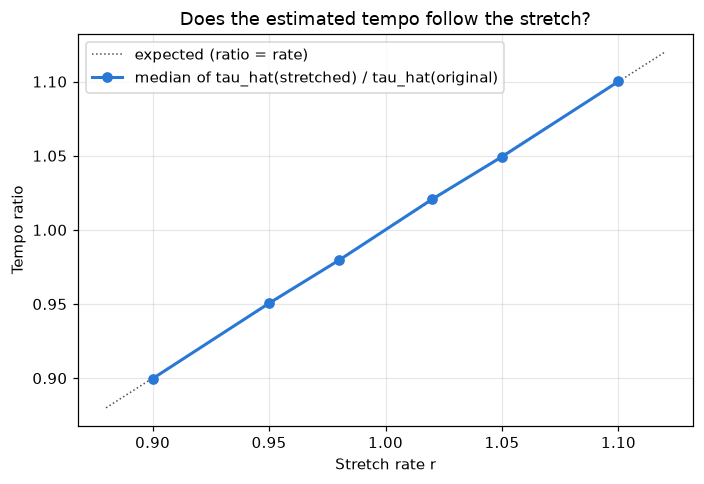

In [8]:
original_tau = data.set_index('filename')['tau_hat']
check_rows = []
for condition in CONDITIONS[1:]:
    part = conditions[conditions['condition'] == condition['condition']].set_index('filename')
    expected_ratio = condition['rate'] if condition['kind'] == 'stretch' else 1.0
    ratio = part['tau_hat']/original_tau.loc[part.index]/expected_ratio
    check_rows.append({'condition': condition['condition'], 'kind': condition['kind'], 'rate': condition['rate'],
                       'expected ratio': expected_ratio, 'median ratio': float(np.median(ratio*expected_ratio)),
                       'within 1% of expected': float(np.mean(np.abs(ratio - 1) < 0.01)),
                       'within 3%': float(np.mean(np.abs(ratio - 1) < 0.03)),
                       'octave jump': float(np.mean((np.abs(ratio - 2) < 0.1) | (np.abs(ratio - 0.5) < 0.05)))})
tempo_check = pd.DataFrame(check_rows)
save(tempo_check, 'comparison', 'tempo_check.csv', index=False)
display(tempo_check.round(3))

figure, axis = plt.subplots(figsize=(6.5, 4.5))
stretch_rows = tempo_check[tempo_check['kind'] == 'stretch']
axis.plot([0.88, 1.12], [0.88, 1.12], color='#52514e', linestyle=':', linewidth=1, label='expected (ratio = rate)')
axis.plot(stretch_rows['rate'], stretch_rows['median ratio'], marker='o', color=BLUE, linewidth=2,
          label='median of tau_hat(stretched) / tau_hat(original)')
axis.set(xlabel='Stretch rate r', ylabel='Tempo ratio', title='Does the estimated tempo follow the stretch?')
axis.grid(alpha=0.3)
axis.legend()
figure.tight_layout()
save_figure(figure, 'comparison', 'tempo_check.png')

## 7. SVM-RBF

The features are scaled inside the pipeline, so the scaler only learns from the training clips. The grid search tries `C` (0.1 to 1000), `gamma` ('scale', 0.001 to 1000) and `class_weight` (None, balanced). It goes up to 1000 because the tempo-only search picked the largest values of a smaller grid: with one input, the boundaries have to be only a few BPM wide.

In [9]:
base_estimator = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale')),
])
parameter_grid = {
    'svm__C': [0.1, 1.0, 10.0, 100.0, 1000.0],
    'svm__gamma': ['scale', 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0],
    'svm__class_weight': [None, 'balanced'],
}

numeric_gammas = [g for g in parameter_grid['svm__gamma'] if g != 'scale']
EDGE_VALUES = {
    'svm__C': [min(parameter_grid['svm__C']), max(parameter_grid['svm__C'])],
    'svm__gamma': [min(numeric_gammas), max(numeric_gammas)],
}


def make_search(inner_cv):
    return GridSearchCV(
        estimator=base_estimator,
        param_grid=parameter_grid,
        scoring={'accuracy': 'accuracy', 'macro_f1': 'f1_macro'},
        refit='macro_f1',
        cv=inner_cv,
        n_jobs=N_JOBS,
        error_score='raise',
    )

## 8. Measures

Accuracy, balanced accuracy, macro precision, macro recall, macro-F1 and weighted F1 on the outer test folds, as mean ± SD over the five folds. Macro-F1 is the main one, because it counts every dance equally. Chance is about 16% accuracy and 12.5% balanced accuracy.

In [10]:
def classification_scores(y_true, y_pred):
    def average(metric, how):
        return metric(y_true, y_pred, labels=class_labels, average=how, zero_division=0)
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_precision': average(precision_score, 'macro'),
        'macro_recall': average(recall_score, 'macro'),
        'macro_f1': average(f1_score, 'macro'),
        'weighted_f1': average(f1_score, 'weighted'),
    }


def summarize_folds(fold_metrics, metrics=METRICS, by=('variant',)):
    summary = fold_metrics.groupby(list(by), sort=False)[metrics].agg(['mean', 'std'])
    summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
    return summary.reset_index()


def mean_sd_table(summary, metrics=METRICS, index='variant'):
    return pd.DataFrame({metric: [f'{100*m:.2f} ± {100*s:.2f}' for m, s in
                                  zip(summary[f'{metric}_mean'], summary[f'{metric}_std'])]
                         for metric in metrics}, index=summary[index]).T


def paired_differences(table_a, table_b, metric='macro_f1', names=('A', 'B')):
    a = table_a.set_index(['fold', 'variant'])[metric]
    b = table_b.set_index(['fold', 'variant'])[metric]
    difference = (100*(b - a)).rename(f'{names[1]} - {names[0]} (pp)').reset_index()
    return difference.pivot(index='fold', columns='variant', values=difference.columns[-1])

## 9. Nested cross-validation

For every outer fold, a default and a tuned model are trained on the other four folds. The tuned settings are chosen by a grid search on three inner folds. The test fold is never used for training or tuning.

In [11]:
@dataclass
class CVResults:
    feature_columns: list
    fold_metrics: pd.DataFrame
    predictions: pd.DataFrame
    best_parameters: pd.DataFrame
    models: dict = field(repr=False)


def run_nested_cv(data, feature_columns, verbose=True):
    fold_rows, parameter_rows, models = [], [], {}
    predictions = data[['filename', 'label', 'group_id', 'fold']].copy()
    for variant in VARIANTS:
        predictions[f'prediction_{variant.lower()}'] = ''

    for fold in sorted(data['fold'].unique()):
        train, test = data['fold'] != fold, data['fold'] == fold
        X_train, y_train = data.loc[train, feature_columns], data.loc[train, 'label']
        X_test, y_test = data.loc[test, feature_columns], data.loc[test, 'label']
        assert not set(data.loc[train, 'group_id']) & set(data.loc[test, 'group_id'])

        default = clone(base_estimator).fit(X_train, y_train)
        inner_cv = StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_SEED + fold)
        search = make_search(inner_cv)
        start = time.perf_counter()
        search.fit(X_train, y_train, groups=data.loc[train, 'group_id'])
        tuning_seconds = time.perf_counter() - start
        tuned = search.best_estimator_

        models[fold] = {'Default': default, 'Tuned': tuned}
        for variant, model in [('Default', default), ('Tuned', tuned)]:
            predicted = model.predict(X_test)
            predictions.loc[test, f'prediction_{variant.lower()}'] = predicted
            fold_rows.append({'fold': fold, 'variant': variant, **classification_scores(y_test, predicted),
                              'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
                              'oob_accuracy': getattr(model, 'oob_score_', np.nan)})
        chosen = {name: ('None' if value is None else value) for name, value in search.best_params_.items()}
        parameter_rows.append({'fold': fold, 'inner_best_macro_f1': search.best_score_, **chosen})
        if verbose:
            d, t = fold_rows[-2], fold_rows[-1]
            print(f'  fold {fold}: accuracy default {d["accuracy"]:.3f} / tuned {t["accuracy"]:.3f}, '
                  f'macro-F1 default {d["macro_f1"]:.3f} / tuned {t["macro_f1"]:.3f} (tuning {tuning_seconds:.1f} s)',
                  flush=True)

    for variant in VARIANTS:
        assert (predictions[f'prediction_{variant.lower()}'] != '').all(), 'a clip was never tested'
    return CVResults(feature_columns, pd.DataFrame(fold_rows), predictions, pd.DataFrame(parameter_rows), models)


cv = {}
for set_name, columns in FEATURE_SETS.items():
    print(f'{set_name} ({len(columns)} inputs)')
    cv[set_name] = run_nested_cv(data, columns)
    save(cv[set_name].fold_metrics, set_name, 'fold_metrics.csv', index=False)
    save(cv[set_name].predictions, set_name, 'out_of_fold_predictions.csv', index=False)
    save(cv[set_name].best_parameters, set_name, 'best_parameters.csv', index=False)

Rhythm (20 inputs)


  fold 1: accuracy default 0.857 / tuned 0.843, macro-F1 default 0.852 / tuned 0.838 (tuning 3.4 s)


  fold 2: accuracy default 0.764 / tuned 0.793, macro-F1 default 0.754 / tuned 0.786 (tuning 1.0 s)


  fold 3: accuracy default 0.821 / tuned 0.864, macro-F1 default 0.813 / tuned 0.860 (tuning 0.9 s)


  fold 4: accuracy default 0.784 / tuned 0.813, macro-F1 default 0.783 / tuned 0.816 (tuning 0.9 s)


...

  fold 1: accuracy default 0.593 / tuned 0.650, macro-F1 default 0.485 / tuned 0.621 (tuning 0.9 s)


  fold 2: accuracy default 0.586 / tuned 0.657, macro-F1 default 0.502 / tuned 0.644 (tuning 0.8 s)


  fold 3: accuracy default 0.650 / tuned 0.693, macro-F1 default 0.552 / tuned 0.675 (tuning 0.8 s)


  fold 4: accuracy default 0.597 / tuned 0.676, macro-F1 default 0.522 / tuned 0.668 (tuning 0.8 s)


  fold 5: accuracy default 0.604 / tuned 0.676, macro-F1 default 0.524 / tuned 0.659 (tuning 0.8 s)


## 10. Results on the original audio

In [12]:
summaries = {}
for set_name, result in cv.items():
    summaries[set_name] = summarize_folds(result.fold_metrics)
    save(summaries[set_name], set_name, 'metric_summary.csv', index=False)

both = pd.concat([s.assign(label=f'{name}, ' + s['variant']) for name, s in summaries.items()])
print('Five outer test folds, mean ± SD (%)')
display(mean_sd_table(both, index='label'))

for set_name, result in cv.items():
    tuning = result.fold_metrics.pivot(index='fold', columns='variant', values='macro_f1')
    print(f'{set_name}: mean macro-F1 change from tuning '
          f'{100*(tuning["Tuned"] - tuning["Default"]).mean():+.2f} percentage points')

Five outer test folds, mean ± SD (%)


label,"Rhythm, Default","Rhythm, Tuned","Tempo only, Default","Tempo only, Tuned"
accuracy,81.23 ± 3.77,82.95 ± 2.75,60.60 ± 2.55,67.05 ± 1.71
balanced_accuracy,80.61 ± 4.12,82.96 ± 3.29,58.65 ± 2.56,66.53 ± 2.33
macro_precision,81.69 ± 4.14,83.57 ± 2.71,61.51 ± 3.12,70.60 ± 2.80
macro_recall,80.61 ± 4.12,82.96 ± 3.29,58.65 ± 2.56,66.53 ± 2.33
macro_f1,80.77 ± 3.95,82.85 ± 2.86,51.70 ± 2.52,65.35 ± 2.14
weighted_f1,81.17 ± 3.56,82.90 ± 2.62,54.39 ± 2.58,65.75 ± 1.98


Rhythm: mean macro-F1 change from tuning +2.08 percentage points
Tempo only: mean macro-F1 change from tuning +13.65 percentage points


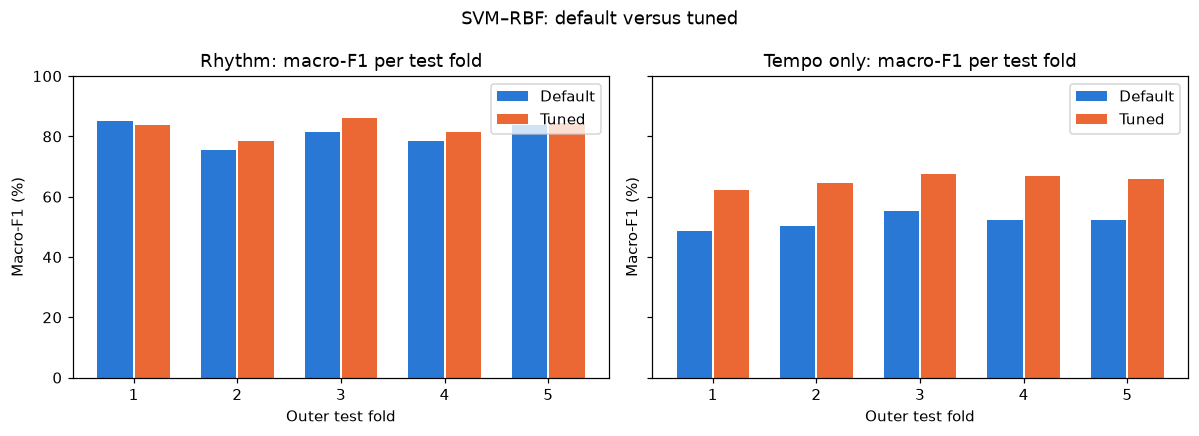

In [13]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, (set_name, result) in zip(axes, cv.items()):
    table = result.fold_metrics.pivot(index='fold', columns='variant', values='macro_f1')[VARIANTS]
    positions = np.arange(len(table))
    for k, (variant, color) in enumerate(zip(VARIANTS, [BLUE, ORANGE])):
        axis.bar(positions + (k - 0.5)*0.36, 100*table[variant], width=0.34, color=color, label=variant)
    axis.set_xticks(positions, table.index)
    axis.set(title=f'{set_name}: macro-F1 per test fold', xlabel='Outer test fold', ylabel='Macro-F1 (%)', ylim=(0, 100))
    axis.legend(loc='upper right')
figure.suptitle(f'{MODEL_NAME}: default versus tuned')
figure.tight_layout()
save_figure(figure, 'comparison', 'fold_performance.png')

## 11. Chosen settings

The settings each fold chose, and the training accuracy next to the test accuracy (a large gap would point to overfitting). The last line counts how often a fold picked a value at the end of the grid.

In [14]:
def count_edge_choices(best_parameters):
    return {name: int(best_parameters[name].isin(ends).sum()) for name, ends in EDGE_VALUES.items()}


for set_name, result in cv.items():
    print(set_name)
    display(result.best_parameters.round(4))
    display(result.fold_metrics[['fold', 'variant', 'train_accuracy', 'accuracy', 'macro_f1']].round(4))
    edge_counts = count_edge_choices(result.best_parameters)
    print(f'folds (of {len(result.best_parameters)}) that chose an end of the grid: {edge_counts}')

Rhythm


,fold,inner_best_macro_f1,svm__C,svm__class_weight,svm__gamma
0,1,0.8148,10.0,None,0.01
1,2,0.8237,10.0,balanced,scale
2,3,0.8229,100.0,balanced,0.001
3,4,0.8248,10.0,None,0.01
4,5,0.8165,10.0,balanced,0.01


,fold,variant,train_accuracy,accuracy,macro_f1
0,1,Default,0.9104,0.8571,0.8519
1,1,Tuned,0.9086,0.8429,0.8380
2,2,Default,0.9068,0.7643,0.7543
3,2,Tuned,0.9857,0.7929,0.7859
4,3,Default,0.9122,0.8214,0.8131
5,3,Tuned,0.9014,0.8643,0.8599
6,4,Default,0.9123,0.7842,0.7831
7,4,Tuned,0.9088,0.8129,0.8157
8,5,Default,0.9106,0.8345,0.8361
9,5,Tuned,0.9123,0.8345,0.8433


folds (of 5) that chose an end of the grid: {'svm__C': 0, 'svm__gamma': 1}
Tempo only


,fold,inner_best_macro_f1,svm__C,svm__class_weight,svm__gamma
0,1,0.6647,1.0,None,1000.0
1,2,0.6593,1.0,None,1000.0
2,3,0.6204,100.0,balanced,100.0
3,4,0.6402,1.0,None,1000.0
4,5,0.6518,1.0,None,1000.0


,fold,variant,train_accuracy,accuracy,macro_f1
0,1,Default,0.6237,0.5929,0.4849
1,1,Tuned,0.7401,0.6500,0.6212
2,2,Default,0.5878,0.5857,0.5022
3,2,Tuned,0.7419,0.6571,0.6443
4,3,Default,0.6039,0.6500,0.5518
5,3,Tuned,0.7133,0.6929,0.6745
6,4,Default,0.6208,0.5971,0.5219
7,4,Tuned,0.7317,0.6763,0.6684
8,5,Default,0.6172,0.6043,0.5243
9,5,Tuned,0.7388,0.6763,0.6591


folds (of 5) that chose an end of the grid: {'svm__C': 0, 'svm__gamma': 4}


## 12. Confusion matrices and errors

Rows are the true dances and columns the predictions, normalised per row. The tempo-only model can only separate dances with different tempi, so its errors show which dances share a tempo.

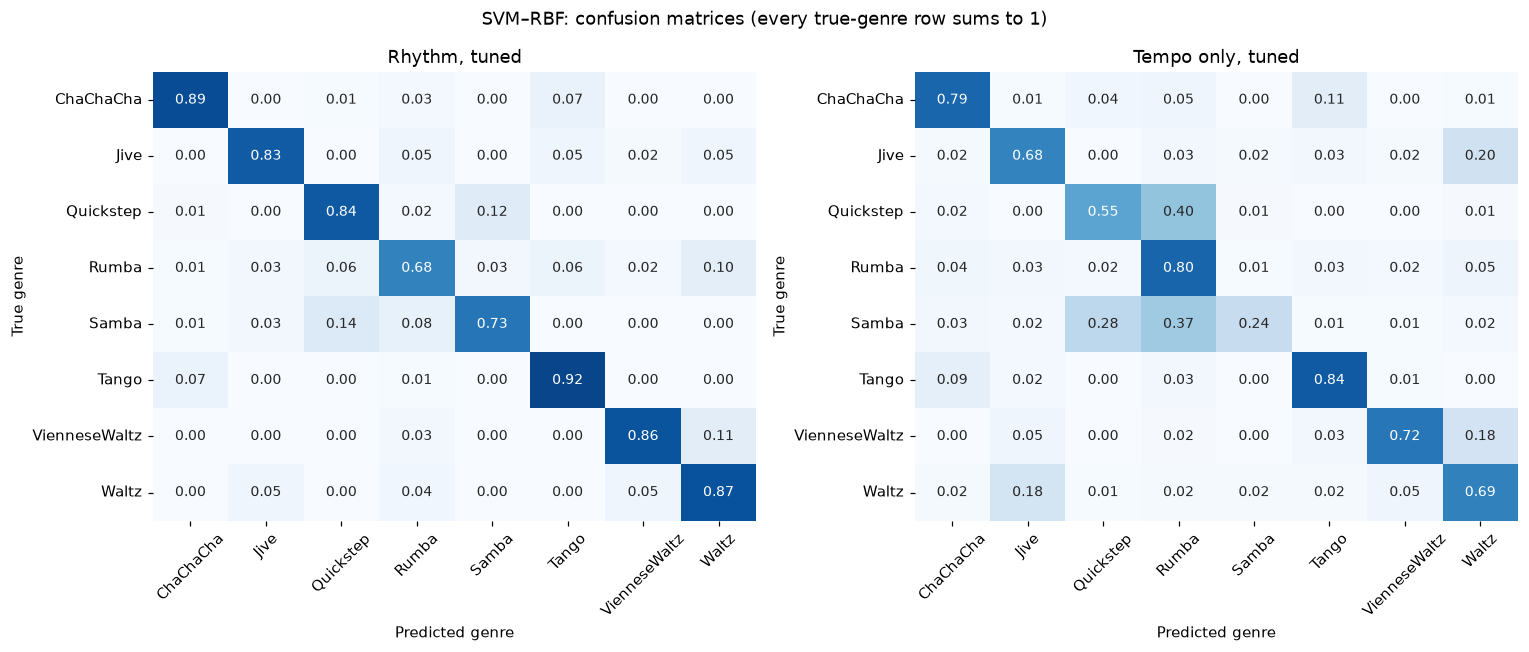

Rhythm, tuned: per-genre precision, recall and F1


,precision,recall,f1-score,support
ChaChaCha,0.9167,0.8919,0.9041,111
Jive,0.8197,0.8333,0.8264,60
Quickstep,0.7841,0.8415,0.8118,82
Rumba,0.7528,0.6837,0.7166,98
Samba,0.8289,0.7326,0.7778,86
Tango,0.8229,0.9186,0.8681,86
VienneseWaltz,0.8750,0.8615,0.8682,65
Waltz,0.8276,0.8727,0.8496,110


Tempo only, tuned: per-genre precision, recall and F1


,precision,recall,f1-score,support
ChaChaCha,0.8148,0.7928,0.8037,111
Jive,0.5694,0.6833,0.6212,60
Quickstep,0.5921,0.5488,0.5696,82
Rumba,0.5000,0.7959,0.6142,98
Samba,0.8077,0.2442,0.3750,86
Tango,0.7660,0.8372,0.8000,86
VienneseWaltz,0.8246,0.7231,0.7705,65
Waltz,0.6972,0.6909,0.6941,110


In [15]:
def confusion_tables(y_true, y_pred):
    counts = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=class_labels), index=class_labels, columns=class_labels)
    return counts, counts.div(counts.sum(axis=1), axis=0)


def plot_confusions(tables, titles, suptitle, ncols=2):
    nrows = int(np.ceil(len(tables)/ncols))
    figure, axes = plt.subplots(nrows, ncols, figsize=(7*ncols, 6*nrows), squeeze=False)
    for axis in axes.flat[len(tables):]:
        axis.set_visible(False)
    for axis, table, title in zip(axes.flat, tables, titles):
        sns.heatmap(table, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=axis, vmin=0, vmax=1, annot_kws={'size': 9})
        axis.set(title=title, xlabel='Predicted genre', ylabel='True genre')
        axis.tick_params(axis='x', rotation=45)
        axis.tick_params(axis='y', rotation=0)
    figure.suptitle(suptitle)
    figure.tight_layout()
    return figure


def per_genre_report(y_true, y_pred):
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=class_labels,
                                                output_dict=True, zero_division=0)).T.loc[class_labels]
    report['support'] = report['support'].astype(int)
    return report


tables, titles = [], []
for set_name, result in cv.items():
    for variant in VARIANTS:
        counts, normalized = confusion_tables(result.predictions['label'], result.predictions[f'prediction_{variant.lower()}'])
        save(counts, set_name, f'confusion_counts_{variant.lower()}.csv')
        save(normalized, set_name, f'confusion_normalized_{variant.lower()}.csv')
        if variant == 'Tuned':
            tables.append(normalized)
            titles.append(f'{set_name}, tuned')
save_figure(plot_confusions(tables, titles, f'{MODEL_NAME}: confusion matrices (every true-genre row sums to 1)'),
            'comparison', 'confusion_normalized_tuned.png')

for set_name, result in cv.items():
    report = per_genre_report(result.predictions['label'], result.predictions['prediction_tuned'])
    save(report, set_name, 'per_genre_report_tuned.csv', index_label='genre')
    print(f'{set_name}, tuned: per-genre precision, recall and F1')
    display(report.round(4))

## 13. Which rhythm features the model uses

We shuffle one group of features at a time across the test clips and look at how much macro-F1 drops. A big drop means the model relies on that group.

,mean macro-F1 drop (pp),SD over folds (pp)
feature_family,,
Cyclic tempogram,63.87,2.05
PLP,19.37,5.79
Bar ratios,2.89,1.58


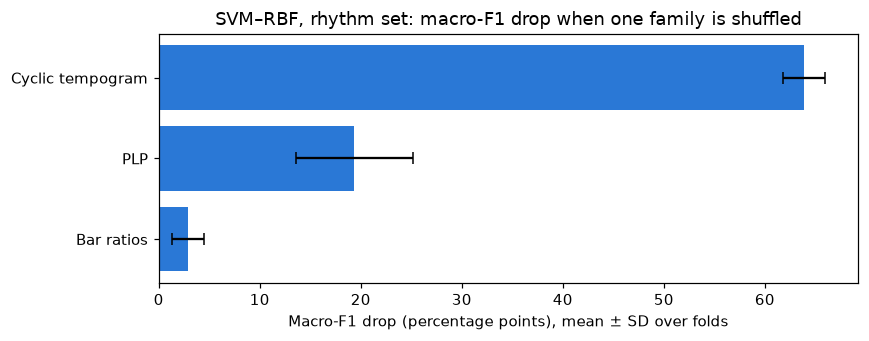

In [16]:
result = cv['Rhythm']
rows = []
for fold, fold_models in result.models.items():
    test = data['fold'] == fold
    X_test, y_test = data.loc[test, RHYTHM_COLUMNS], data.loc[test, 'label']
    model = fold_models['Tuned']
    baseline = f1_score(y_test, model.predict(X_test), average='macro', zero_division=0)
    for family, columns in FEATURE_GROUPS.items():
        for repeat in range(IMPORTANCE_REPEATS):
            order = np.random.default_rng(RANDOM_SEED + 100*fold + repeat).permutation(len(X_test))
            shuffled = X_test.copy()
            shuffled[columns] = X_test[columns].to_numpy()[order]
            score = f1_score(y_test, model.predict(shuffled), average='macro', zero_division=0)
            rows.append({'fold': fold, 'feature_family': family, 'macro_f1_drop': baseline - score})
per_fold = pd.DataFrame(rows).groupby(['fold', 'feature_family'])['macro_f1_drop'].mean()
importance = per_fold.groupby('feature_family').agg(['mean', 'std']).sort_values('mean', ascending=False)
save(importance, 'Rhythm', 'feature_family_importance.csv')
display((100*importance).rename(columns={'mean': 'mean macro-F1 drop (pp)', 'std': 'SD over folds (pp)'}).round(2))

figure, axis = plt.subplots(figsize=(8, 3.2))
positions = np.arange(len(importance))
axis.barh(positions, 100*importance['mean'], xerr=100*importance['std'], color=BLUE, capsize=4)
axis.set_yticks(positions, importance.index)
axis.invert_yaxis()
axis.axvline(0, color='#52514e', linewidth=1)
axis.set(title=f'{MODEL_NAME}, rhythm set: macro-F1 drop when one family is shuffled',
         xlabel='Macro-F1 drop (percentage points), mean ± SD over folds')
figure.tight_layout()
save_figure(figure, 'Rhythm', 'feature_family_importance.png')

## 14. SVM-RBF vs Random Forest

Both notebooks use the same folds, so we compare them fold by fold. This needs `Rhythm_Random_Forest.ipynb` to have run first.

In [17]:
for set_name in FEATURE_SETS:
    other_path = OTHER_RESULTS_DIR / SET_DIRS[set_name] / 'fold_metrics.csv'
    if not other_path.is_file():
        print(f'{set_name}: run the {OTHER_MODEL_NAME} notebook, then rerun this cell.')
        continue
    other = pd.read_csv(other_path)
    pair = pd.concat([summarize_folds(cv[set_name].fold_metrics, ['accuracy', 'macro_f1']).assign(model=MODEL_NAME),
                      summarize_folds(other, ['accuracy', 'macro_f1']).assign(model=OTHER_MODEL_NAME)])
    pair['label'] = pair['model'] + ', ' + pair['variant']
    print(f'{set_name}: same recordings and folds, mean ± SD (%)')
    display(mean_sd_table(pair, ['accuracy', 'macro_f1'], index='label'))
    print(f'{set_name}: per fold, macro-F1 of {MODEL_NAME} minus {OTHER_MODEL_NAME} (percentage points)')
    display(paired_differences(other, cv[set_name].fold_metrics, names=(OTHER_MODEL_NAME, MODEL_NAME)).round(2))

Rhythm: same recordings and folds, mean ± SD (%)


label,"SVM–RBF, Default","SVM–RBF, Tuned","Random Forest, Default","Random Forest, Tuned"
accuracy,81.23 ± 3.77,82.95 ± 2.75,82.81 ± 2.43,82.24 ± 2.19
macro_f1,80.77 ± 3.95,82.85 ± 2.86,82.27 ± 2.67,81.76 ± 2.56


Rhythm: per fold, macro-F1 of SVM–RBF minus Random Forest (percentage points)


variant,Default,Tuned
fold,,
1,-0.05,0.23
2,-2.74,0.42
3,-2.41,5.68
4,-3.20,-0.63
5,0.90,-0.22


Tempo only: same recordings and folds, mean ± SD (%)


label,"SVM–RBF, Default","SVM–RBF, Tuned","Random Forest, Default","Random Forest, Tuned"
accuracy,60.60 ± 2.55,67.05 ± 1.71,61.31 ± 2.98,65.90 ± 3.56
macro_f1,51.70 ± 2.52,65.35 ± 2.14,60.12 ± 2.90,64.80 ± 3.33


Tempo only: per fold, macro-F1 of SVM–RBF minus Random Forest (percentage points)


variant,Default,Tuned
fold,,
1,-11.57,-0.94
2,-7.89,0.59
3,-9.94,-3.24
4,-6.71,4.20
5,-5.95,2.14


---
## 15. Time-stretch experiment

From here on, the models from section 9 are only used for prediction, on the stretched and round-trip versions. Each version keeps its label and test fold, so we compare the same clips with the same model. If a model relies on the tempo, it gets worse as the stretch grows, while the round trip barely hurts it.

In [18]:
def evaluate_conditions(result, columns):
    by_condition = {name: rows.set_index('filename') for name, rows in conditions.groupby('condition')}
    metric_rows, prediction_rows = [], []
    for fold, fold_models in result.models.items():
        test_files = data.loc[data['fold'] == fold, 'filename']
        y_test = data.loc[data['fold'] == fold, 'label'].to_numpy()
        for variant, model in fold_models.items():
            baseline = model.predict(by_condition['original'].loc[test_files, columns])
            baseline_scores = classification_scores(y_test, baseline)
            for condition in CONDITIONS:
                predicted = model.predict(by_condition[condition['condition']].loc[test_files, columns])
                scores = classification_scores(y_test, predicted)
                metric_rows.append({'fold': fold, 'variant': variant, **condition, **scores,
                                    'flip_rate': np.mean(predicted != baseline),
                                    'accuracy_change_pp': 100*(scores['accuracy'] - baseline_scores['accuracy']),
                                    'macro_f1_change_pp': 100*(scores['macro_f1'] - baseline_scores['macro_f1'])})
                prediction_rows.append(pd.DataFrame({'filename': test_files.to_numpy(), 'label': y_test, 'fold': fold,
                                                     'variant': variant, 'condition': condition['condition'],
                                                     'prediction': predicted, 'baseline_prediction': baseline}))
    return pd.DataFrame(metric_rows), pd.concat(prediction_rows, ignore_index=True)


condition_metrics, condition_predictions, stretch_summary = {}, {}, {}
for set_name, columns in FEATURE_SETS.items():
    condition_metrics[set_name], condition_predictions[set_name] = evaluate_conditions(cv[set_name], columns)
    stretch_summary[set_name] = summarize_folds(
        condition_metrics[set_name], ['accuracy', 'macro_f1', 'flip_rate', 'accuracy_change_pp', 'macro_f1_change_pp'],
        by=('variant', 'condition', 'kind', 'rate', 'tempo_change_percent'))
    folder = RESULTS_DIR / SET_DIRS[set_name] / 'time_stretch'
    condition_metrics[set_name].to_csv(folder / 'fold_metrics.csv', index=False)
    condition_predictions[set_name].to_csv(folder / 'held_out_predictions.csv', index=False)
    stretch_summary[set_name].to_csv(folder / 'robustness_summary.csv', index=False)
print('evaluated', ', '.join(FEATURE_SETS), 'on all', len(CONDITIONS), 'versions')

evaluated Rhythm, Tempo only on all 13 versions


## 16. Results per version

Mean ± SD over the five test folds; the change is measured against the original audio within each fold.

In [19]:
for set_name, summary in stretch_summary.items():
    table = summary[['variant', 'condition', 'tempo_change_percent']].copy()
    for metric in ['accuracy', 'macro_f1', 'flip_rate']:
        table[f'{metric} (%)'] = [f'{100*m:.2f} ± {100*s:.2f}' for m, s in
                                  zip(summary[f'{metric}_mean'], summary[f'{metric}_std'])]
    table['macro-F1 change (pp)'] = summary['macro_f1_change_pp_mean'].round(2)
    print(set_name)
    display(table.reset_index(drop=True))

Rhythm


,variant,condition,tempo_change_percent,accuracy (%),macro_f1 (%),flip_rate (%),macro-F1 change (pp)
0,Default,original,0.0,81.23 ± 3.77,80.77 ± 3.95,0.00 ± 0.00,0.00
1,Default,stretch_0.90,-10.0,32.23 ± 6.50,25.33 ± 6.66,65.05 ± 4.84,-55.44
2,Default,stretch_0.95,-5.0,50.28 ± 2.20,43.29 ± 2.84,45.99 ± 3.85,-37.48
3,Default,stretch_0.98,-2.0,68.33 ± 2.94,66.23 ± 3.02,25.07 ± 3.89,-14.54
4,Default,stretch_1.02,2.0,70.05 ± 4.75,69.17 ± 4.79,26.94 ± 3.88,-11.60
5,Default,stretch_1.05,5.0,36.54 ± 3.18,35.90 ± 3.36,60.88 ± 4.98,-44.87
6,Default,stretch_1.10,10.0,12.76 ± 2.64,11.91 ± 3.39,87.68 ± 1.06,-68.86
7,Default,roundtrip_0.90,0.0,76.22 ± 3.03,74.17 ± 3.38,14.04 ± 2.31,-6.60
8,Default,roundtrip_0.95,0.0,74.93 ± 2.75,73.16 ± 2.97,14.47 ± 2.65,-7.61
9,Default,roundtrip_0.98,0.0,75.93 ± 2.62,73.90 ± 2.88,15.76 ± 2.62,-6.88


Tempo only


,variant,condition,tempo_change_percent,accuracy (%),macro_f1 (%),flip_rate (%),macro-F1 change (pp)
0,Default,original,0.0,60.60 ± 2.55,51.70 ± 2.52,0.00 ± 0.00,0.00
1,Default,stretch_0.90,-10.0,29.80 ± 0.88,20.64 ± 1.35,66.47 ± 4.57,-31.06
2,Default,stretch_0.95,-5.0,43.27 ± 3.96,33.95 ± 3.40,42.83 ± 3.10,-17.75
3,Default,stretch_0.98,-2.0,54.58 ± 3.22,44.70 ± 3.24,19.90 ± 3.67,-7.01
4,Default,stretch_1.02,2.0,55.87 ± 2.62,46.04 ± 2.23,14.76 ± 2.77,-5.66
5,Default,stretch_1.05,5.0,41.69 ± 1.77,33.17 ± 1.39,33.81 ± 1.99,-18.54
6,Default,stretch_1.10,10.0,18.91 ± 4.08,15.06 ± 3.82,71.63 ± 5.33,-36.65
7,Default,roundtrip_0.90,0.0,59.31 ± 2.81,50.62 ± 2.21,5.44 ± 1.92,-1.08
8,Default,roundtrip_0.95,0.0,59.45 ± 2.51,50.67 ± 1.43,5.16 ± 1.70,-1.03
9,Default,roundtrip_0.98,0.0,59.88 ± 2.04,51.04 ± 1.19,5.30 ± 1.64,-0.67


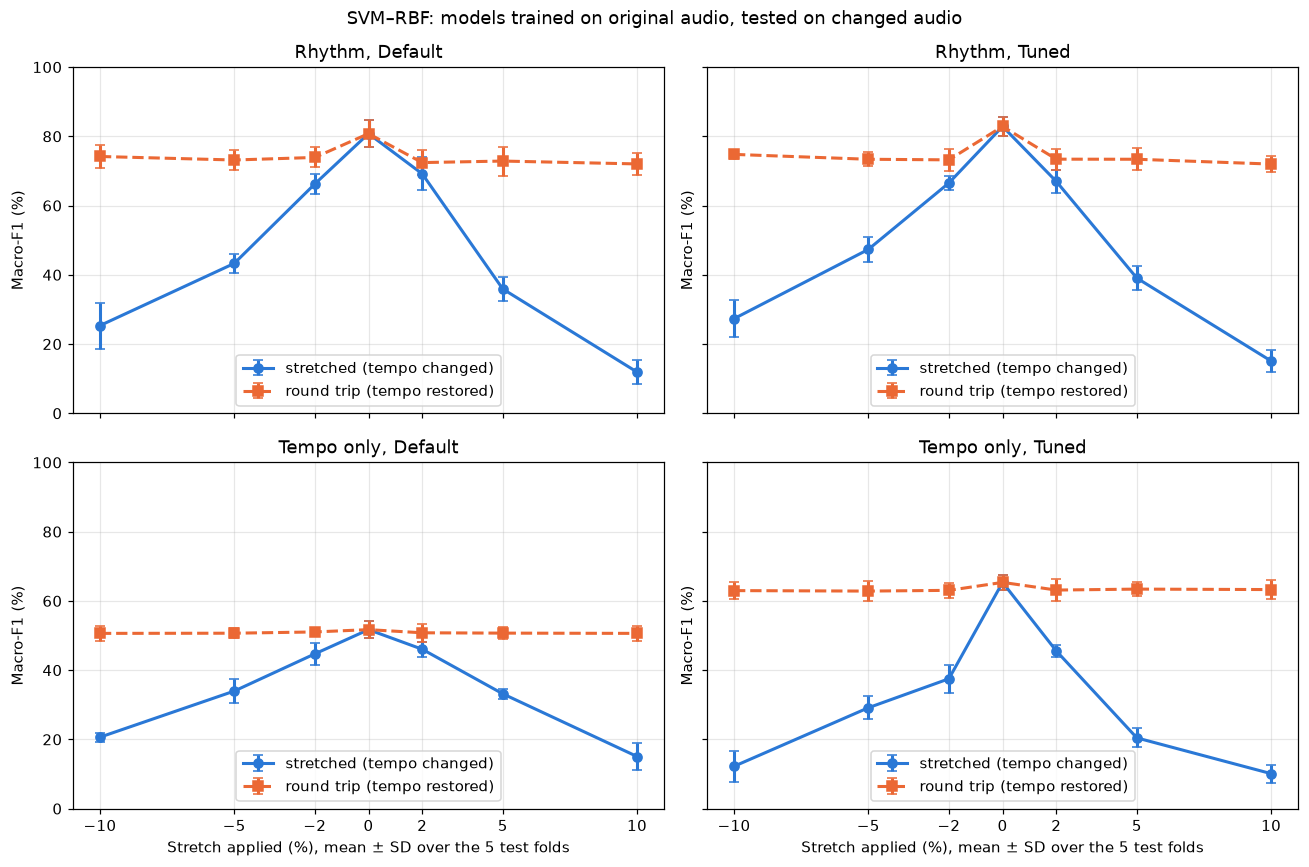

In [20]:
LINES = [('stretch', BLUE, '-', 'o', 'stretched (tempo changed)'),
         ('roundtrip', ORANGE, '--', 's', 'round trip (tempo restored)')]

figure, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for row, (set_name, summary) in enumerate(stretch_summary.items()):
    for col, variant in enumerate(VARIANTS):
        axis = axes[row, col]
        rows = summary[summary['variant'] == variant]
        for kind, color, style, marker, legend in LINES:
            part = rows[rows['kind'].isin([kind, 'original'])].sort_values('rate')
            axis.errorbar(100*(part['rate'] - 1), 100*part['macro_f1_mean'], yerr=100*part['macro_f1_std'],
                          color=color, linestyle=style, marker=marker, markersize=6, linewidth=2, capsize=3, label=legend)
        axis.set(ylim=(0, 100), ylabel='Macro-F1 (%)', title=f'{set_name}, {variant}')
        axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
        axis.grid(alpha=0.3)
        axis.legend(loc='lower center')
for axis in axes[1]:
    axis.set_xlabel('Stretch applied (%), mean ± SD over the 5 test folds')
figure.suptitle(f'{MODEL_NAME}: models trained on original audio, tested on changed audio')
figure.tight_layout()
save_figure(figure, 'comparison', 'robustness_curves.png')

## 17. Confusion matrices and per-dance changes

Confusion matrices at −10% and +10%, and the change in F1 per dance for every version (blue better, red worse).

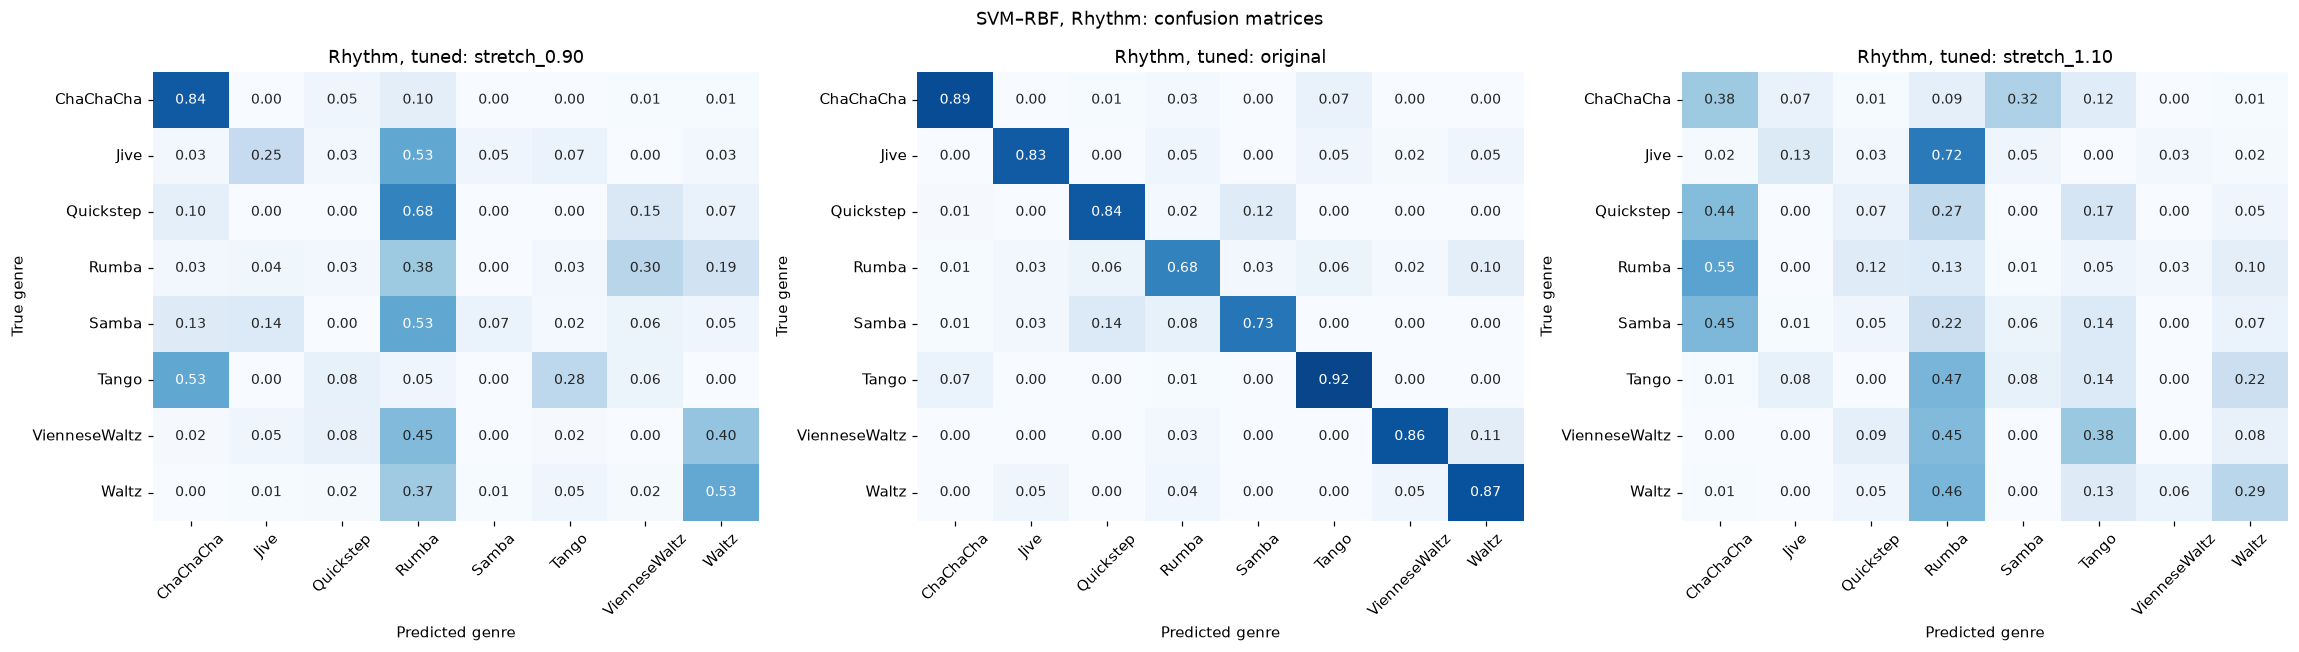

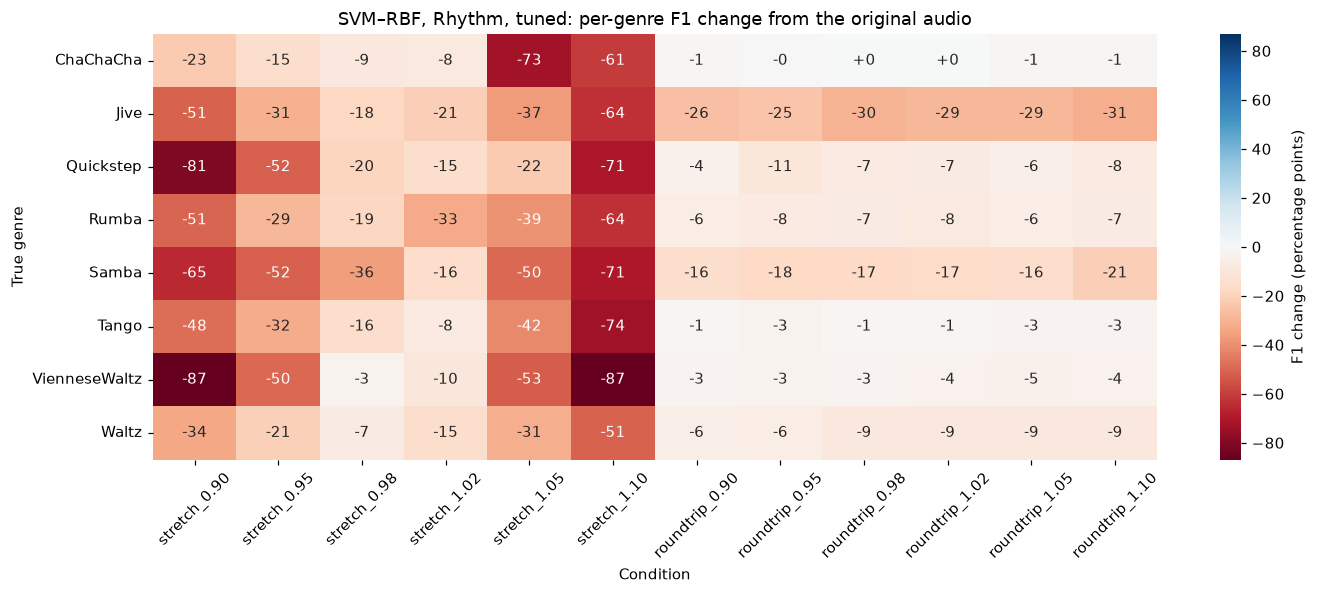

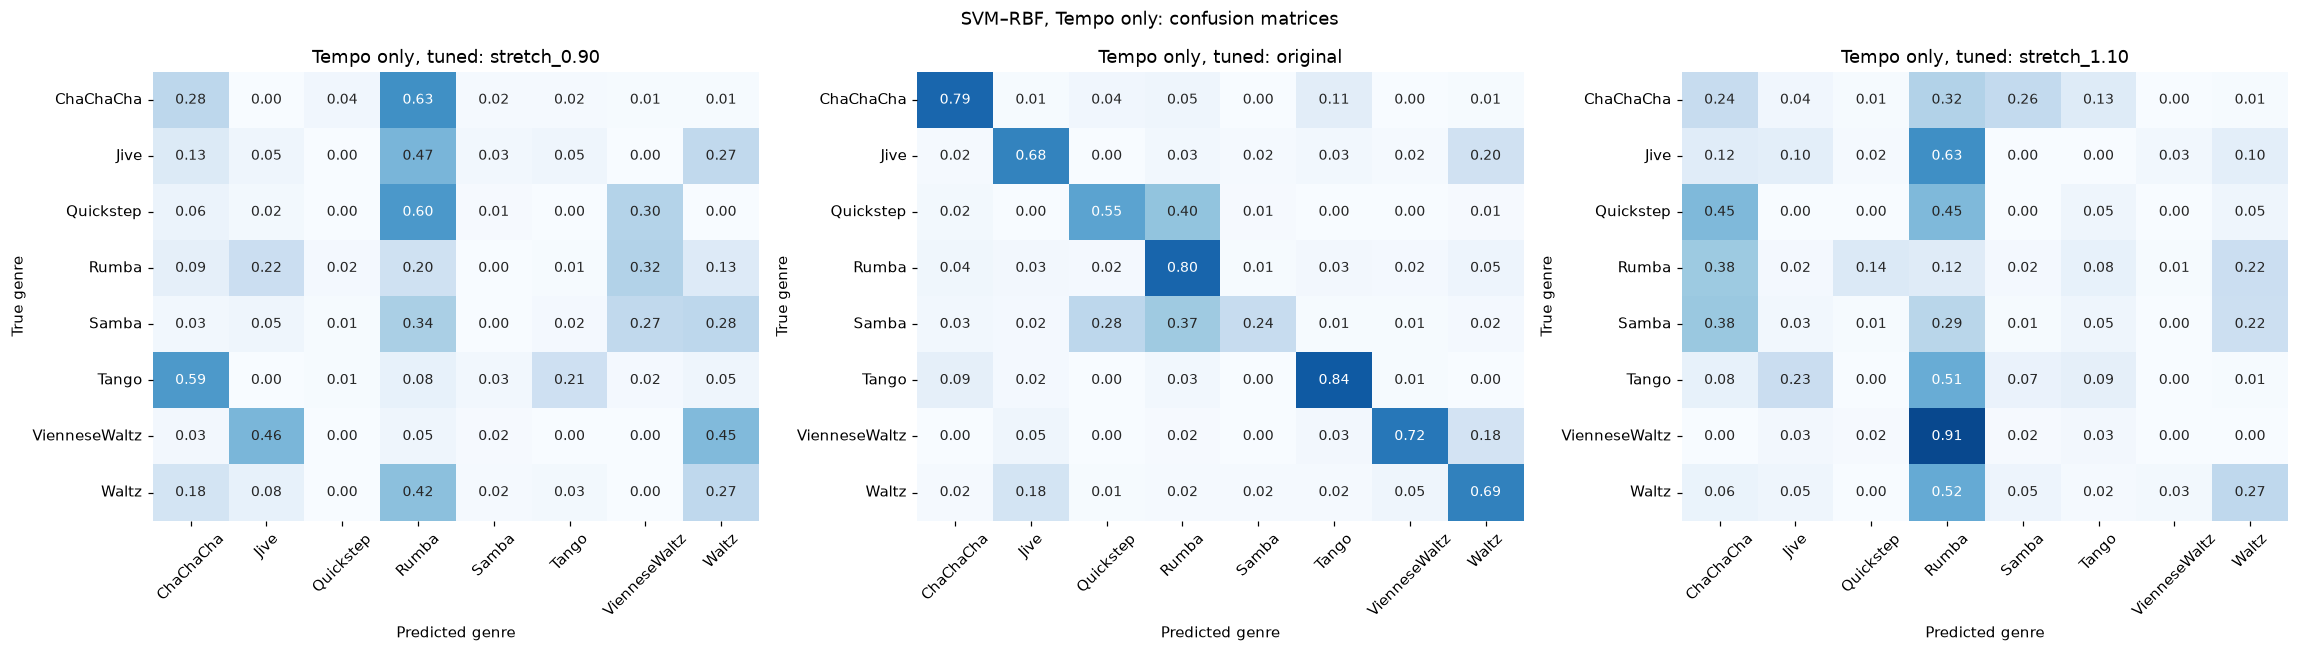

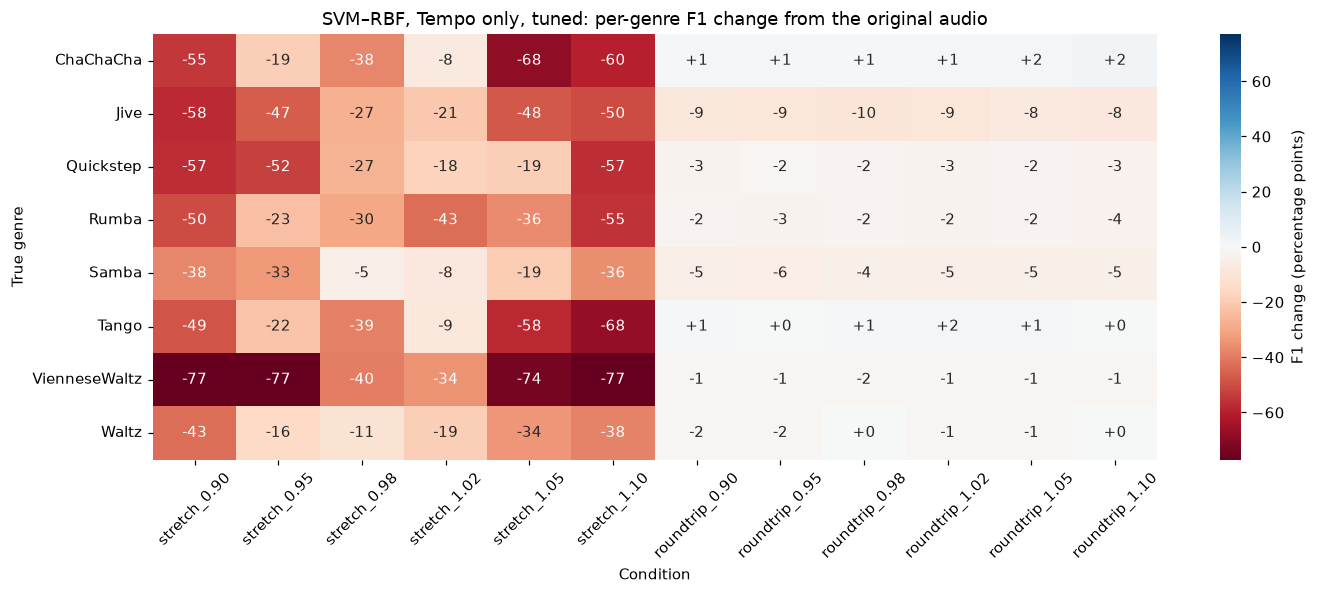

In [21]:
for set_name in FEATURE_SETS:
    tuned = condition_predictions[set_name][condition_predictions[set_name]['variant'] == 'Tuned']
    tables, titles = [], []
    for name in ['stretch_0.90', 'original', 'stretch_1.10']:
        rows = tuned[tuned['condition'] == name]
        tables.append(confusion_tables(rows['label'], rows['prediction'])[1])
        titles.append(f'{set_name}, tuned: {name}')
    save_figure(plot_confusions(tables, titles, f'{MODEL_NAME}, {set_name}: confusion matrices', ncols=3),
                set_name, 'time_stretch/confusion_normalized.png')

    f1_by_condition = pd.DataFrame({name: per_genre_report(rows['label'], rows['prediction'])['f1-score']
                                    for name, rows in tuned.groupby('condition')})[CONDITION_ORDER]
    f1_by_condition.to_csv(RESULTS_DIR / SET_DIRS[set_name] / 'time_stretch' / 'per_genre_f1_tuned.csv')
    changes = 100*f1_by_condition[CONDITION_ORDER[1:]].sub(f1_by_condition['original'], axis=0)
    bound = max(1.0, float(np.abs(changes.to_numpy()).max()))
    figure, axis = plt.subplots(figsize=(13, 5.5))
    sns.heatmap(changes, annot=True, fmt='+.0f', cmap='RdBu', center=0, vmin=-bound, vmax=bound, ax=axis,
                cbar_kws={'label': 'F1 change (percentage points)'})
    axis.set(title=f'{MODEL_NAME}, {set_name}, tuned: per-genre F1 change from the original audio',
             xlabel='Condition', ylabel='True genre')
    axis.tick_params(axis='x', rotation=45)
    axis.tick_params(axis='y', rotation=0)
    figure.tight_layout()
    save_figure(figure, set_name, 'time_stretch/per_genre_f1_change.png')

## 18. Both classifiers on the stretched audio

This needs the time-stretch part of `Rhythm_Random_Forest.ipynb`.

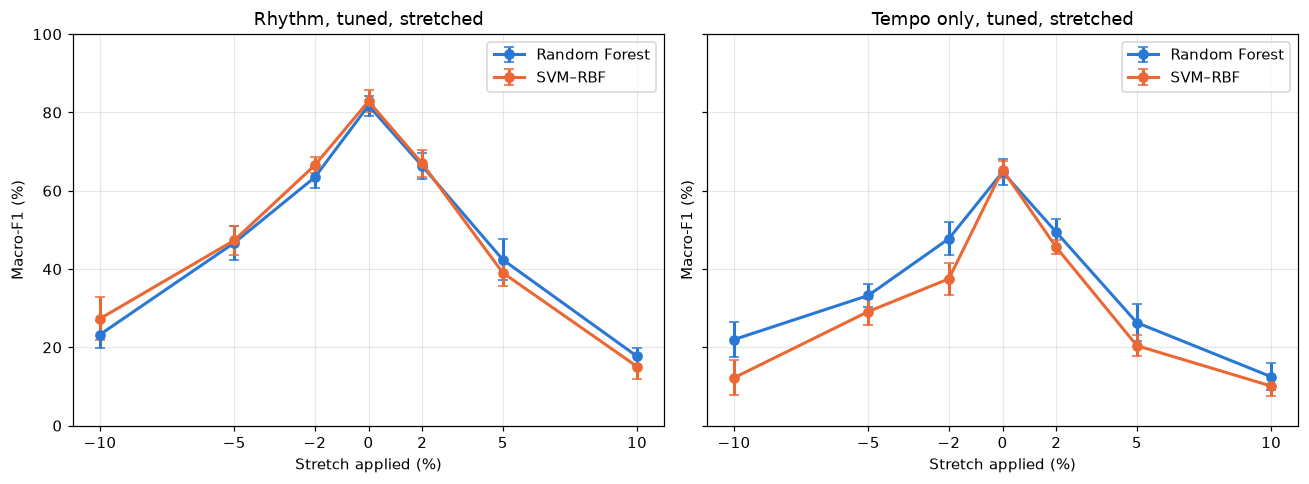

In [22]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
missing = []
for axis, set_name in zip(axes, FEATURE_SETS):
    other_path = OTHER_RESULTS_DIR / SET_DIRS[set_name] / 'time_stretch' / 'robustness_summary.csv'
    if not other_path.is_file():
        missing.append(set_name)
        continue
    combined = pd.concat([stretch_summary[set_name].assign(model=MODEL_NAME), pd.read_csv(other_path).assign(model=OTHER_MODEL_NAME)])
    for model, rows in combined[combined['variant'] == 'Tuned'].groupby('model'):
        rows = rows[rows['kind'].isin(['stretch', 'original'])].sort_values('rate')
        axis.errorbar(100*(rows['rate'] - 1), 100*rows['macro_f1_mean'], yerr=100*rows['macro_f1_std'], marker='o',
                      capsize=3, linewidth=2, label=model, color=MODEL_COLORS[model])
    axis.set(title=f'{set_name}, tuned, stretched', xlabel='Stretch applied (%)', ylabel='Macro-F1 (%)', ylim=(0, 100))
    axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
    axis.grid(alpha=0.3)
    axis.legend()
if missing:
    plt.close(figure)
    print(f'Run the time-stretch sections of the {OTHER_MODEL_NAME} notebook, then rerun this cell.')
else:
    figure.tight_layout()
    save_figure(figure, 'comparison', 'model_comparison.png')

## 19. Timbral vs rhythm vs tempo only

The three feature sets with the same model. A set that relies on the tempo gets worse as the stretch grows, while the round trip hardly hurts it. The timbral results are read from `results/svm_rbf/`.

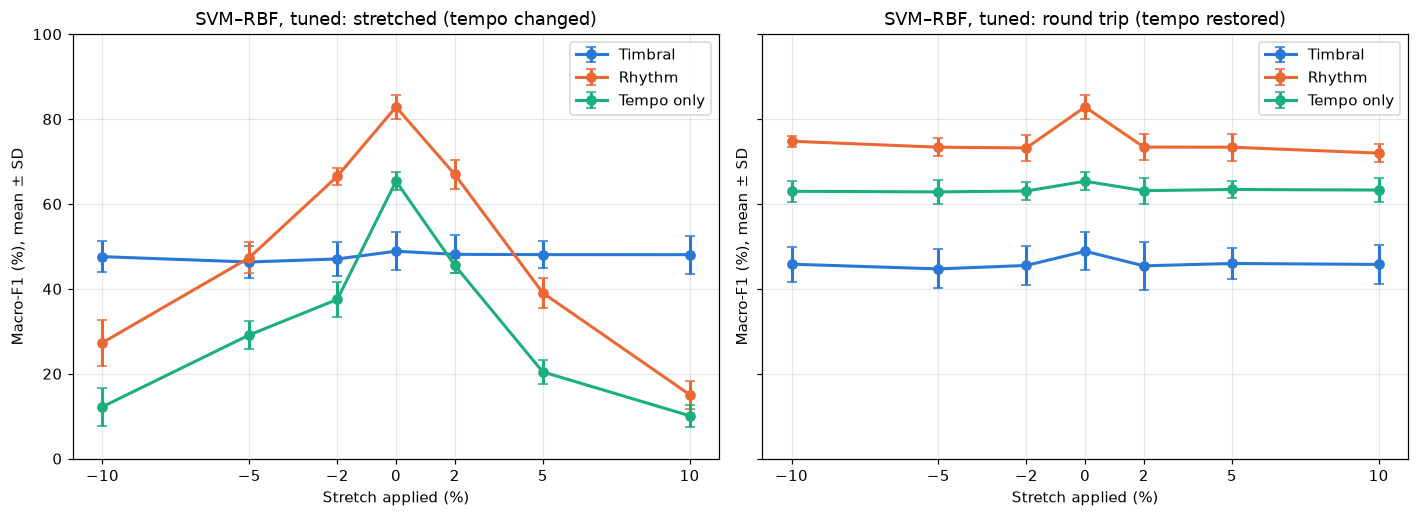

,original macro-F1 (%),"mean change, stretch (pp)","mean change, round trip (pp)",change at -10% (pp),change at +10% (pp),"mean flip rate, stretch (%)"
feature set,,,,,,
Timbral,48.86,-1.33,-3.33,-1.28,-0.81,14.71
Rhythm,82.85,-39.14,-9.50,-55.53,-67.76,52.13
Tempo only,65.35,-39.52,-2.23,-53.12,-55.24,68.43


In [23]:
curves = {name: summary for name, summary in stretch_summary.items()}
timbral_path = TIMBRAL_RESULTS_DIR / 'time_stretch' / 'robustness_summary.csv'
if timbral_path.is_file():
    curves = {'Timbral': pd.read_csv(timbral_path), **curves}
else:
    print(f'{timbral_path} not found: run the timbral notebook of the same model to add it.')

figure, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for axis, kind, title in zip(axes, ['stretch', 'roundtrip'], ['stretched (tempo changed)', 'round trip (tempo restored)']):
    for set_name, summary in curves.items():
        rows = summary[(summary['variant'] == 'Tuned') & summary['kind'].isin([kind, 'original'])].sort_values('rate')
        axis.errorbar(100*(rows['rate'] - 1), 100*rows['macro_f1_mean'], yerr=100*rows['macro_f1_std'], marker='o',
                      capsize=3, linewidth=2, color=SET_COLORS[set_name], label=set_name)
    axis.set(title=f'{MODEL_NAME}, tuned: {title}', xlabel='Stretch applied (%)', ylabel='Macro-F1 (%), mean ± SD',
             ylim=(0, 100))
    axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
    axis.grid(alpha=0.3)
    axis.legend()
figure.tight_layout()
save_figure(figure, 'comparison', 'feature_set_comparison.png')

rows = []
for set_name, summary in curves.items():
    tuned = summary[summary['variant'] == 'Tuned'].set_index('condition')
    rows.append({'feature set': set_name,
                 'original macro-F1 (%)': 100*tuned.loc['original', 'macro_f1_mean'],
                 'mean change, stretch (pp)': tuned.loc[tuned['kind'] == 'stretch', 'macro_f1_change_pp_mean'].mean(),
                 'mean change, round trip (pp)': tuned.loc[tuned['kind'] == 'roundtrip', 'macro_f1_change_pp_mean'].mean(),
                 'change at -10% (pp)': tuned.loc['stretch_0.90', 'macro_f1_change_pp_mean'],
                 'change at +10% (pp)': tuned.loc['stretch_1.10', 'macro_f1_change_pp_mean'],
                 'mean flip rate, stretch (%)': 100*tuned.loc[tuned['kind'] == 'stretch', 'flip_rate_mean'].mean()})
overview = pd.DataFrame(rows).set_index('feature set')
save(overview, 'comparison', 'feature_set_overview.csv')
display(overview.round(2))